<a href="https://colab.research.google.com/github/XmanujaX/LLM_Lab03/blob/main/LLM_Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab3

## Step 1

In [1]:
!pip install torch datasets transformers gradio matplotlib

In [2]:
from datasets import load_dataset

ds = load_dataset("roneneldan/TinyStoriesInstruct")

TinyStories-Instruct-train.txt: reconstructing file:   0%|          |  0.00B / 2.66GB            

TinyStories-Instruct-train.txt: downloading bytes:           |  0.00B            

TinyStories-Instruct-valid.txt: reconstructing file:   0%|          |  0.00B / 26.9MB            

TinyStories-Instruct-valid.txt: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/21755681 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/218380 [00:00<?, ? examples/s]

In [3]:
print(ds)
print("Sample story:", ds["train"][0])
print("Sample story:", ds["train"][1])

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 21755681
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 218380
    })
})
Sample story: {'text': 'Features: Dialogue'}
Sample story: {'text': 'Words: quit, oak, gloomy'}


## Step 2

In [ ]:
#Select the subset size and adjest
sub_size=5000
texts=[ds['train'][i]['text']for i in range(sub_size)]
full_txt=" ".join(texts)

#Build character level tokenizer
chars=sorted(list(set(full_txt)))
vocab_size=len(chars)
print(f"Vocab size: {vocab_size}")
print(f"Characters: {''.join(chars)}")

#Create mapping from character to integer back
stoi={ch:i for i,ch in enumerate(chars)}
itos={i:ch for i,ch in enumerate(chars)}

#Encode and Decode
encode=lambda s:[stoi[c] for c in s]
decode=lambda l:''.join([itos[i] for i in l])

#Example
sample="Once upon a time"
encoded=encode(sample)
print(f"Encoded: {encoded}")
print(f"Decoded: {decode(encoded)}")

Vocab size: 65
Characters:  !"',-.17:<>?ABCDEFGHIJKLMNOPQRSTUVWYZabcdefghijklmnopqrstuvwxyz|
Encoded: [27, 51, 40, 42, 0, 58, 53, 52, 51, 0, 38, 0, 57, 46, 50, 42]
Decoded: Once upon a time


## Step 3

In [ ]:
import torch

#Encode all the txt into a single tensor
data=torch.tensor(encode(full_txt),dtype=torch.long)

#Split into training and validation
n=int(0.9*len(data))
train_data=data[:n]
val_data=data[n:]

#Hypoparameter for batching
block_s=128
batch_s=32

def get_batch(split):
    data_split=train_data if split=='train' else val_data
    #Genarate random starting indices
    ix=torch.randint(len(data_split)-block_s,(batch_s,))
    #stack input sequences
    x=torch.stack([data_split[i:i+block_s] for i in ix])
    #stack target sequence(shifted by 1)
    y=torch.stack([data_split[i+1:i+block_s+1] for i in ix])
    return x,y

#Test the batch genarattion
xb,yb=get_batch('train')
print(f"Input shape: {xb.shape}")
print(f"Target shape: {yb.shape}")
print(f"Sample input: {xb[0][:20]}")
print(f"Sample target: {yb[0][:20]}")


Input shape: torch.Size([32, 128])
Target shape: torch.Size([32, 128])
Sample input: tensor([57, 38, 48, 42, 56,  0, 57, 45, 42,  0, 53, 42, 51,  0, 38, 51, 41,  0,
        56, 40])
Sample target: tensor([38, 48, 42, 56,  0, 57, 45, 42,  0, 53, 42, 51,  0, 38, 51, 41,  0, 56,
        40, 55])


## Step 4

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import math

class Head(nn.Module):
  """One head of self-attention"""
  def __init__(self, head_size):
    super().__init__()
    self.key = nn.Linear(n_embd, head_size, bias=False)
    self.query = nn.Linear(n_embd, head_size, bias=False)
    self.value = nn.Linear(n_embd, head_size, bias=False)
    self.register_buffer('tril', torch.tril(torch.ones(block_s, block_s)))
    self.dropout = nn.Dropout(dropout)

  def forward(self, x):
    B, T, C = x.shape
    k = self.key(x) # (B, T, head_size)
    q = self.query(x) # (B, T, head_size)
    # compute attention scores ("affinities")
    # Scale by the square root of head_size (which is C here for a single head's output dimension)
    wei = q @ k.transpose(-2, -1) * (k.shape[-1]**-0.5)
    wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
    wei = F.softmax(wei, dim=-1)
    wei = self.dropout(wei)
    # perform the weighted aggregation of the values
    v = self.value(x) # (B, T, head_size)
    out = wei @ v # (B, T, head_size)
    return out

class MultiHeadAttention(nn.Module):
  """Multiple heads of self-attention in parallel"""
  def __init__(self, num_heads, head_size):
    super().__init__()
    self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
    self.proj = nn.Linear(n_embd, n_embd)
    self.dropout = nn.Dropout(dropout)

  def forward(self, x):
    out = torch.cat([h(x) for h in self.heads], dim=-1)
    out = self.dropout(self.proj(out))
    return out

class FeedForward(nn.Module):
    """A simple linear layer followed by a non-linearity."""
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """Transformer block: communication followed by computation."""
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        # Each token maps to a vector of size n_embd
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        # Each position maps to a vector of size n_embd
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        # Stack of Transformer blocks
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # Final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size) # Language model head

    def forward(self, idx, targets=None):
        B, T = idx.shape
        # idx and targets are both (B, T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T, C)
        x = tok_emb + pos_emb # (B, T, C)
        x = self.blocks(x) # (B, T, C)
        x = self.ln_f(x) # (B, T, C)
        logits = self.lm_head(x) # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # Crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # Get the predictions
            logits, loss = self(idx_cond)
            # Focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # Apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # Append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

## Step 5

In [ ]:
# Hyperparameters
batch_size = 32
block_size = 128
max_iters = 5000
eval_interval = 500
learning_rate = 3e-4
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 128
n_head = 4
n_layer = 4
dropout = 0.2

# Create the model
model=TinyTransformer()
m = model.to(device)

# Print the number of parameters
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# Create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

0.824897 M parameters


## Step 6

In [ ]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            X, Y = X.to(device), Y.to(device)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

# Training loop
for iter in range(max_iters):
    # Every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    # Sample a batch of data
    xb, yb = get_batch('train')
    xb, yb = xb.to(device), yb.to(device)

    # Evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step 0: train loss 4.3751, val loss 4.3699
step 500: train loss 2.1739, val loss 2.2541
step 1000: train loss 1.7681, val loss 1.8626
step 1500: train loss 1.5541, val loss 1.6237
step 2000: train loss 1.4245, val loss 1.4992
step 2500: train loss 1.3391, val loss 1.4064
step 3000: train loss 1.2738, val loss 1.3523
step 3500: train loss 1.2235, val loss 1.3024
step 4000: train loss 1.1837, val loss 1.2685
step 4500: train loss 1.1491, val loss 1.2354
step 4999: train loss 1.1308, val loss 1.2152


In [ ]:
# Reconstruct the metrics from your completed training logs so you can plot them without retraining!
steps = [0, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 4999]
train_losses = [4.3751, 2.1739, 1.7681, 1.5541, 1.4245, 1.3391, 1.2738, 1.2235, 1.1837, 1.1491, 1.1308]
val_losses = [4.3699, 2.2541, 1.8626, 1.6237, 1.4992, 1.4064, 1.3523, 1.3024, 1.2685, 1.2354, 1.2152]
print("Populated 'steps', 'train_losses', and 'val_losses' from training logs. You can now re-run the plot cell!")

Populated 'steps', 'train_losses', and 'val_losses' from training logs. You can now re-run the plot cell!


## Step 7

In [ ]:
import matplotlib.pyplot as plt

# (You would need to modify the training loop to store the loss values)
# For demonstration, here is how you might plot them:
# Assuming you have lists: train_losses, val_losses, and steps
# plt.figure(figsize=(10, 5))
# plt.plot(steps, train_losses, label='Train Loss')
# plt.plot(steps, val_losses, label='Validation Loss')
# plt.xlabel('Steps')
# plt.ylabel('Loss')
# plt.legend()
# plt.title('Training and Validation Loss')
# plt.show()

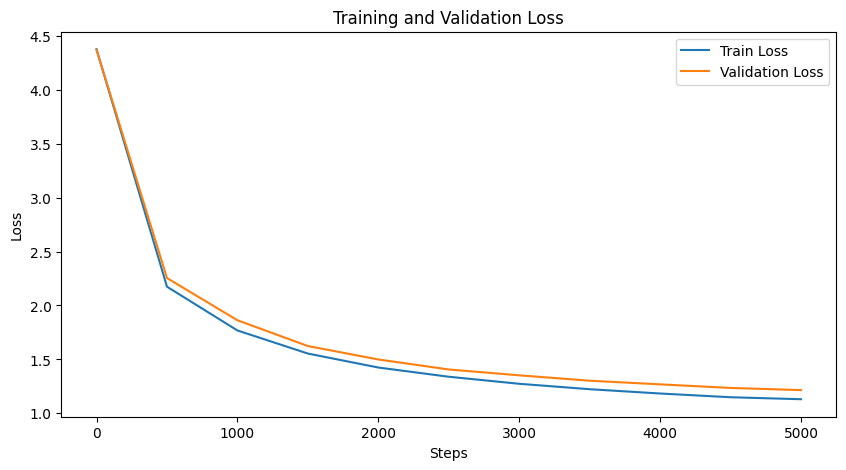

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(steps, train_losses, label='Train Loss')
plt.plot(steps, val_losses, label='Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

## Step 8

In [ ]:
# Evaluate on the validation set
model.eval()
val_losses = []
with torch.no_grad():
    for _ in range(eval_iters):
        X, Y = get_batch('val')
        X, Y = X.to(device), Y.to(device)
        logits, loss = model(X, Y)
        val_losses.append(loss.item())

avg_val_loss = sum(val_losses) / len(val_losses)
perplexity = math.exp(avg_val_loss)

print(f"Validation Loss: {avg_val_loss:.4f}")
print(f"Perplexity: {perplexity:.2f}")

Validation Loss: 1.2144
Perplexity: 3.37


## Step 9

In [ ]:
# Start with a prompt
prompt = "Once upon a time"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

# Generate text
generated_ids = model.generate(context, max_new_tokens=500)[0].tolist()
generated_text = decode(generated_ids)

print("--- Generated Story ---")
print(generated_text)

--- Generated Story ---
Once upon a time stick to find the bell. She had laughed it another. He bad on a give. She smole were was pretends! She had a big ball doesn't I am fun. They wanted to came on the showe. Tom and Lily are tried eady. Lily and happy. She rust of and new toys the cried in the green with the fun. "Let's go to the man bad ful Ben't. Cop!" They said and Ben friends. "Mom, something it Sam, Lily. She said. Thank you, decided!" "Hey, Sara are drive your and said, "Yes, I did, noisy go be came of the part. You come coul


## Step 10

In [ ]:
# Example: Increase model capacity
# n_layer = 6
# n_head = 8
# n_embd = 256
# max_iters = 10000

In [ ]:
n_layer = 6
n_head = 8
n_embd = 256
max_iters = 10000

## Step 11

In [ ]:
# Save the model weights
torch.save(model.state_dict(), 'tiny_transformer.pth')

# Save the configuration
config = {
    'vocab_size': vocab_size,
    'block_size': block_size,
    'n_embd': n_embd,
    'n_head': n_head,
    'n_layer': n_layer,
    'stoi': stoi,
    'itos': itos
}
import json
with open('model_config.json', 'w') as f:
    json.dump(config, f)

## Build a Gardio web

In [ ]:
import gradio as gr

def chat_with_model(prompt):
    """Generate a response from the model given a prompt."""
    context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    generated_ids = model.generate(context, max_new_tokens=1000)[0].tolist()
    return decode(generated_ids)

# Create the Gradio interface
iface = gr.Interface(
    fn=chat_with_model,
    inputs=gr.Textbox(label="Your Prompt", placeholder="Once upon a time..."),
    outputs=gr.Textbox(label="Generated Story"),
    title="TinyStories Transformer Chat",
    description="Enter a prompt and the model will generate a story."
)

# Launch the app
iface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://992cfce2f8d01fddf2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
